In [1]:
# We use the following techniques to avoid underfitting and overfitting:
# 1.Lasso Regression: L1 regularization, adds a penalty equal to the absolute value of the magnitude of coefficients.
# 2.Ridge Regression: L2 regularization, adds a penalty equal to the square of the magnitude of coefficients.
# 3.Elastic Net: Combination of L1 and L2

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
insurance_df = pd.read_csv("../data/insurance.csv")
insurance_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
#Feature Engineering
X = insurance_df.drop(columns=["charges"])
y = insurance_df["charges"]
X = pd.get_dummies(X, columns=["region","sex","smoker"], drop_first=True,dtype=int)  # Convert categorical variables to dummy variables
print("independent variables: ", X.columns)
print("dependent variable: ", y.name)
X['bmi_smoker_interaction'] = X['bmi'] * X['smoker_yes']
X['age_smoker_interaction'] = X['age'] * X['smoker_yes']
X.head()

independent variables:  Index(['age', 'bmi', 'children', 'region_northwest', 'region_southeast',
       'region_southwest', 'sex_male', 'smoker_yes'],
      dtype='object')
dependent variable:  charges


,age,bmi,children,region_northwest,region_southeast,region_southwest,sex_male,smoker_yes,bmi_smoker_interaction,age_smoker_interaction
0,19,27.900,0,0,0,1,0,1,27.9,19
1,18,33.770,1,0,1,0,1,0,0.0,0
2,28,33.000,3,0,1,0,1,0,0.0,0
3,33,22.705,0,1,0,0,1,0,0.0,0
4,32,28.880,0,1,0,0,1,0,0.0,0


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print("R-squared: ", r2)

R-squared:  0.8652316979531681


In [7]:

from sklearn import linear_model
clf = linear_model.Lasso(alpha=0.5)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rms = np.sqrt(mse)
print("Root Mean Squared Error: ", rms)

Root Mean Squared Error:  4573.69120751099


In [9]:
lambda_values = [0.01, 0.1, 1,2, 5, 10,20,30,40, 50,100]
rmse_values = []
for lambda_value in lambda_values:
    clf = linear_model.Lasso(alpha=lambda_value)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rms = np.sqrt(mse)
    rmse_values.append(rms)
    print(f"Lambda: {lambda_value}, Root Mean Squared Error: {rms}")

Lambda: 0.01, Root Mean Squared Error: 4574.114933583564
Lambda: 0.1, Root Mean Squared Error: 4574.036019206616
Lambda: 1, Root Mean Squared Error: 4573.275097082675
Lambda: 2, Root Mean Squared Error: 4572.50902445395
Lambda: 5, Root Mean Squared Error: 4570.560894546705
Lambda: 10, Root Mean Squared Error: 4568.559954041461
Lambda: 20, Root Mean Squared Error: 4569.200001730365
Lambda: 30, Root Mean Squared Error: 4575.806808700219
Lambda: 40, Root Mean Squared Error: 4587.752103751805
Lambda: 50, Root Mean Squared Error: 4604.147487663542
Lambda: 100, Root Mean Squared Error: 4735.445074426543


Text(0.5, 1.0, 'Effect of Lambda on RMSE for Lasso Regression')

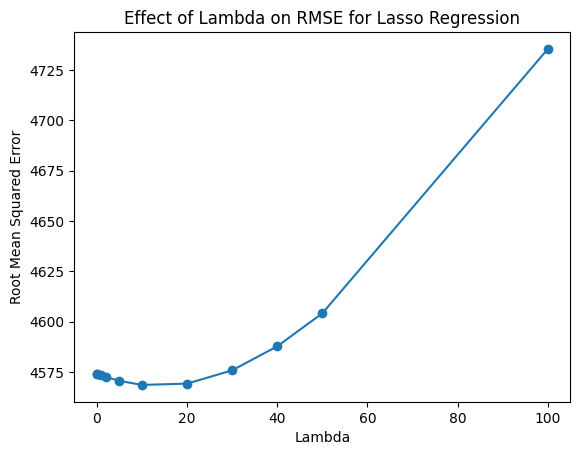

In [10]:
import matplotlib.pyplot as plt
plt.plot(lambda_values, rmse_values, marker='o')
plt.xlabel('Lambda')
plt.ylabel('Root Mean Squared Error')
plt.title('Effect of Lambda on RMSE for Lasso Regression')

In [15]:
clf = linear_model.LassoCV(alphas=lambda_values, cv=5, max_iter=1000, random_state=42)
clf.fit(X_train, y_train)
best_lambda = clf.alpha_
print("Best Lambda: ", best_lambda)
y_pred = clf.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rms = np.sqrt(mse)
print("Root Mean Squared Error with Best Lambda: ", rms)
r2 = r2_score(y_test, y_pred)
print("R-squared with Best Lambda: ", r2)

Best Lambda:  0.01
Root Mean Squared Error with Best Lambda:  4574.114933583564
R-squared with Best Lambda:  0.8652322165560442


In [19]:
clf = linear_model.RidgeCV(alphas=lambda_values, cv=5)
clf.fit(X_train, y_train)
best_lambda = clf.alpha_
print("Best Lambda: ", best_lambda)
y_pred = clf.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rms = np.sqrt(mse)
print("Root Mean Squared Error with Best Lambda: ", rms)
r2 = r2_score(y_test, y_pred)
print("R-squared with Best Lambda: ", r2)

Best Lambda:  0.01
Root Mean Squared Error with Best Lambda:  4573.916686918514
R-squared with Best Lambda:  0.8652438982409321


In [20]:
# Elastic Net = L1 (Lasso) + L2 (Ridge)
# penalty = alpha * [ l1_ratio * |w|  +  (1 - l1_ratio)/2 * w^2 ]
#   l1_ratio = 1   -> pure Lasso  (some coefficients become exactly 0)
#   l1_ratio = 0   -> pure Ridge  (coefficients shrink, none become 0)
#   0 < l1_ratio < 1 -> mix: Lasso's feature selection + Ridge's stability with correlated features
# alpha controls the overall strength; l1_ratio controls the L1/L2 mix.
l1_ratios = [0.1, 0.3, 0.5, 0.7, 0.9, 1]

clf = linear_model.ElasticNetCV(l1_ratio=l1_ratios, alphas=lambda_values, cv=5,
                                max_iter=10000, random_state=42)
clf.fit(X_train, y_train)
print("Best Lambda (alpha): ", clf.alpha_)
print("Best l1_ratio: ", clf.l1_ratio_)
y_pred = clf.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
rms = np.sqrt(mse)
print("Root Mean Squared Error with Best Lambda: ", rms)
r2 = r2_score(y_test, y_pred)
print("R-squared with Best Lambda: ", r2)
print("Coefficients set to zero:", int(np.sum(clf.coef_ == 0)), "of", len(clf.coef_))

Best Lambda (alpha):  0.01
Best l1_ratio:  1.0
Root Mean Squared Error with Best Lambda:  4574.114933583564
R-squared with Best Lambda:  0.8652322165560442
Coefficients set to zero: 0 of 10
